Dataset Loaded Successfully!
Dataset Shape: (225745, 79)

Traffic Distribution:
Attack
1    128025
0     97686
Name: count, dtype: int64

Sampled Dataset Shape: (40000, 8)

Network Event Classification Results

Accuracy: 49.5 %

Classification Report:
                precision    recall  f1-score   support

Normal Traffic       0.50      0.99      0.66      4000
   DDoS Attack       0.00      0.00      0.00      4000

      accuracy                           0.49      8000
     macro avg       0.25      0.49      0.33      8000
  weighted avg       0.25      0.49      0.33      8000



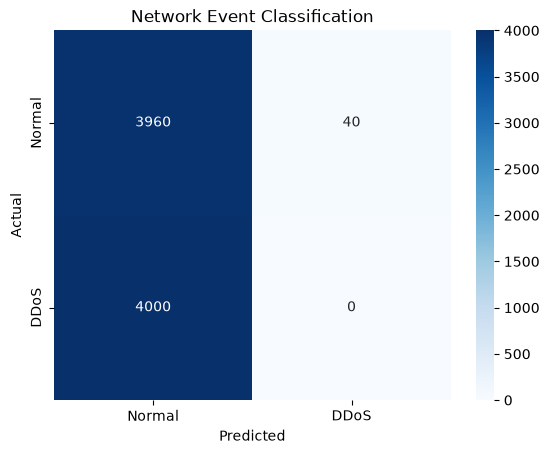


Sample Predictions:
        Actual Predicted
0  DDoS Attack    Normal
1       Normal    Normal
2  DDoS Attack    Normal
3  DDoS Attack    Normal
4  DDoS Attack    Normal
5       Normal    Normal
6       Normal    Normal
7       Normal    Normal
8       Normal    Normal
9       Normal    Normal

Results saved successfully!


In [4]:
# Program 10: Network Event Classification Using K-Means

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report, confusion_matrix

# 1. Load Dataset
df = pd.read_csv("network_events.csv", low_memory=False)

print("Dataset Loaded Successfully!")
print("Dataset Shape:", df.shape)

# 2. Clean Column Names
df.columns = df.columns.str.strip()

# 3. Select Features
features = [
    'Flow Duration',
    'Total Fwd Packets',
    'Total Backward Packets',
    'Flow Bytes/s',
    'Flow Packets/s',
    'SYN Flag Count',
    'ACK Flag Count',
    'Packet Length Mean'
]

# 4. Check Required Columns
required_columns = features + ['Label']

missing = [col for col in required_columns if col not in df.columns]

if missing:
    raise ValueError("Missing columns in dataset: " + str(missing))

# 5. Clean Data
for col in features:
    df[col] = pd.to_numeric(df[col], errors='coerce')

df = df.replace([np.inf, -np.inf], np.nan)
df = df.dropna(subset=features + ['Label']).copy()

# 6. Create Target Variable
df['Attack'] = (
    df['Label'].astype(str).str.strip().str.upper() != 'BENIGN'
).astype(int)

print("\nTraffic Distribution:")
print(df['Attack'].value_counts())

# 7. Separate Features and Target
X = df[features].copy()
y = df['Attack'].copy()

# 8. Sample Data Without GroupBy
normal_index = y[y == 0].sample(
    n=min(20000, (y == 0).sum()),
    random_state=42
).index

attack_index = y[y == 1].sample(
    n=min(20000, (y == 1).sum()),
    random_state=42
).index

selected_index = normal_index.union(attack_index)

X = X.loc[selected_index].copy()
y = y.loc[selected_index].copy()

print("\nSampled Dataset Shape:", X.shape)

# 9. Split Dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# 10. Select Normal Training Traffic
X_normal = X_train[y_train == 0]

# 11. Apply Standard Scaling
scaler = StandardScaler()

X_normal_scaled = scaler.fit_transform(X_normal)
X_test_scaled = scaler.transform(X_test)

# 12. Train K-Means
kmeans = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)

kmeans.fit(X_normal_scaled)

# 13. Calculate Anomaly Threshold
train_distances = kmeans.transform(
    X_normal_scaled
).min(axis=1)

threshold = np.percentile(train_distances, 99)

# 14. Predict Network Events
test_distances = kmeans.transform(
    X_test_scaled
).min(axis=1)

y_pred = (test_distances > threshold).astype(int)

# 15. Evaluate Results
print("\nNetwork Event Classification Results")

print("\nAccuracy:",
      round(accuracy_score(y_test, y_pred) * 100, 2), "%")

print("\nClassification Report:")

print(classification_report(
    y_test,
    y_pred,
    target_names=['Normal Traffic', 'DDoS Attack'],
    zero_division=0
))

# 16. Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Normal', 'DDoS'],
    yticklabels=['Normal', 'DDoS']
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Network Event Classification")
plt.show()

# 17. Save Results
results = pd.DataFrame({
    'Actual': y_test.to_numpy(),
    'Predicted': y_pred
})

results['Actual'] = results['Actual'].map({
    0: 'Normal',
    1: 'DDoS Attack'
})

results['Predicted'] = results['Predicted'].map({
    0: 'Normal',
    1: 'DDoS Attack'
})

results.to_csv("network_event_results.csv", index=False)

print("\nSample Predictions:")
print(results.head(10))

print("\nResults saved successfully!")